# UPI Fraud Detection — Exploratory Data Analysis

This notebook explores the project’s **synthetic** UPI transaction dataset. It is designed to be run from the project root in Jupyter. It covers data quality, class imbalance, transaction values, time patterns, categories, apps, fraud types, and numeric relationships.

> **Important:** The dataset is artificially generated with injected fraud patterns. Findings and model metrics are educational and should not be interpreted as real-world UPI performance.

## 1. Setup and load data

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "data" / "upi_transactions.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "upi_transactions.csv"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df["is_fraud"] = df["is_fraud"].fillna(0).astype(int)
df["fraud_type"] = df["fraud_type"].fillna("legitimate")
df["hour"] = df["timestamp"].dt.hour
df["day"] = df["timestamp"].dt.floor("D")
df["month"] = df["timestamp"].dt.to_period("M").astype(str)

sns.set_theme(style="whitegrid", context="notebook")
print(f"Rows: {len(df):,} | Columns: {df.shape[1]} | Date range: {df.timestamp.min()} to {df.timestamp.max()}")
df.head()

Rows: 10,000 | Columns: 18 | Date range: 2026-01-01 00:49:34 to 2026-09-27 21:09:07


,transaction_id,upi_ref_no,timestamp,sender_name,sender_vpa,sender_bank,upi_app,receiver_name,receiver_vpa,txn_type,category,amount_inr,status,is_fraud,fraud_type,hour,day,month
0,TXN69CEBADA76BEDD,589462321665,2026-01-01 00:49:34,Aditya Iyer,adityaiyer230@ybl,Canara,PhonePe,Swiggy,swiggy@axl,P2M,Food,69.82,SUCCESS,0,legitimate,0,2026-01-01,2026-01
1,TXN1B9E90C12581BB,580397530214,2026-01-01 04:06:04,Imran Mehta,imranmehta293@paytm,SBI,Paytm,Meesho,meesho@paytm,P2M,Shopping,21.00,SUCCESS,0,legitimate,4,2026-01-01,2026-01
2,TXNAE9921EA3DCBD2,780511503627,2026-01-01 07:23:23,Lakshmi Singh,lakshmisingh317@okaxis,Bank of Baroda,Google Pay,Rohan Kumar,rohankumar25@okaxis,P2P,Transfer,145.00,SUCCESS,0,legitimate,7,2026-01-01,2026-01
3,TXN238AC0D50F90F3,177144998052,2026-01-01 07:45:03,Ananya Iyer,ananyaiyer395@upi,Kotak,BHIM,DMart,dmart@okicici,P2M,Groceries,457.00,SUCCESS,0,legitimate,7,2026-01-01,2026-01
4,TXN53FFD1752D7125,759158923898,2026-01-01 08:48:09,Rohan Patel,rohanpatel390@ybl,Kotak,PhonePe,Ananya Khan,ananyakhan111@ybl,P2P,Transfer,14.00,SUCCESS,0,legitimate,8,2026-01-01,2026-01


## 2. Data dictionary and quality checks

In [2]:
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "missing_pct": (100 * df.isna().mean()).round(2), "unique_values": df.nunique()}))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate transaction IDs:", int(df["transaction_id"].duplicated().sum()))
print("Non-positive amounts:", int((df["amount_inr"] <= 0).sum()))
print("Fraud label counts:")
display(df["is_fraud"].value_counts().rename(index={0: "Legitimate", 1: "Fraud"}).to_frame("transactions"))

,dtype,missing,missing_pct,unique_values
transaction_id,object,0,0.0,10000
upi_ref_no,int64,0,0.0,10000
timestamp,datetime64[ns],0,0.0,9999
sender_name,object,0,0.0,285
sender_vpa,object,0,0.0,400
sender_bank,object,0,0.0,8
upi_app,object,0,0.0,4
receiver_name,object,0,0.0,332
receiver_vpa,object,0,0.0,457
txn_type,object,0,0.0,2


Exact duplicate rows: 0
Duplicate transaction IDs: 0
Non-positive amounts: 0
Fraud label counts:


,transactions
is_fraud,
Legitimate,9694
Fraud,306


## 3. Executive summary

In [3]:
summary = pd.Series({
    "Transactions": len(df),
    "Unique senders": df["sender_vpa"].nunique(),
    "Unique receivers": df["receiver_vpa"].nunique(),
    "Fraud transactions": int(df["is_fraud"].sum()),
    "Fraud rate (%)": round(100 * df["is_fraud"].mean(), 2),
    "Total transaction value (INR)": round(df["amount_inr"].sum(), 2),
    "Mean transaction amount (INR)": round(df["amount_inr"].mean(), 2),
    "Median transaction amount (INR)": round(df["amount_inr"].median(), 2),
})
display(summary.to_frame("value"))

,value
Transactions,10000.00
Unique senders,400.00
Unique receivers,457.00
Fraud transactions,306.00
Fraud rate (%),3.06
Total transaction value (INR),4010947.89
Mean transaction amount (INR),401.09
Median transaction amount (INR),227.73


## 4. Class balance

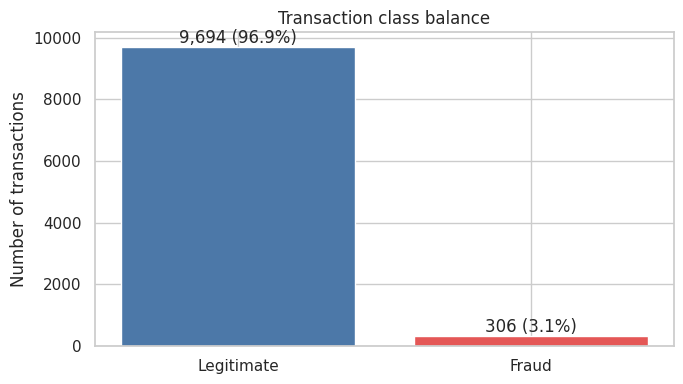

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = df["is_fraud"].map({0: "Legitimate", 1: "Fraud"}).value_counts().reindex(["Legitimate", "Fraud"])
ax.bar(counts.index, counts.values, color=["#4c78a8", "#e45756"])
ax.set_title("Transaction class balance")
ax.set_ylabel("Number of transactions")
for i, v in enumerate(counts.values): ax.text(i, v, f"{v:,} ({v / len(df):.1%})", ha="center", va="bottom")
plt.tight_layout(); plt.savefig(REPORTS / "eda_class_balance.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Transaction amount distribution

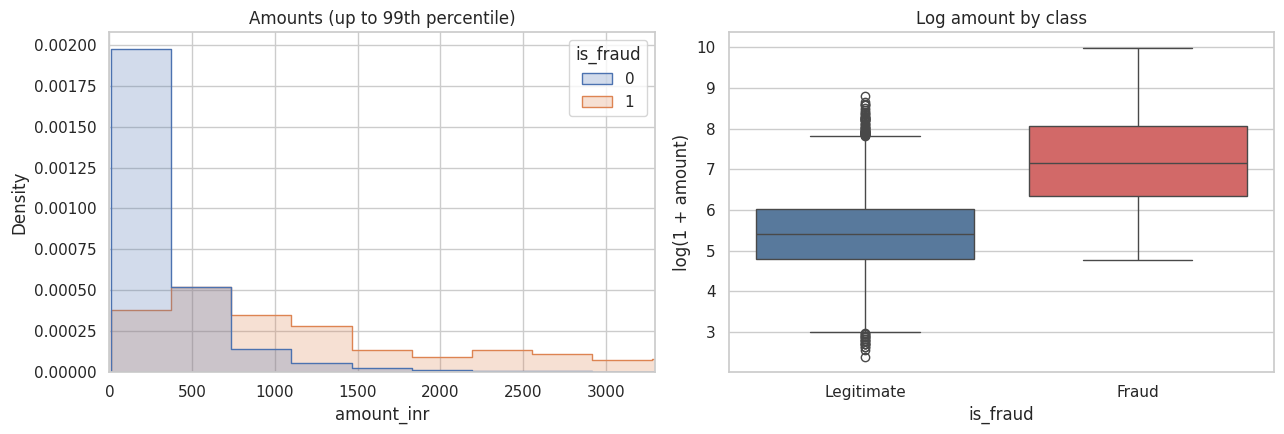

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="amount_inr", hue="is_fraud", bins=60, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_xlim(0, df["amount_inr"].quantile(.99)); axes[0].set_title("Amounts (up to 99th percentile)")
df["log_amount"] = np.log1p(df["amount_inr"])
sns.boxplot(data=df, x="is_fraud", y="log_amount", ax=axes[1], palette=["#4c78a8", "#e45756"])
axes[1].set_xticklabels(["Legitimate", "Fraud"]); axes[1].set_title("Log amount by class"); axes[1].set_ylabel("log(1 + amount)")
plt.tight_layout(); plt.savefig(REPORTS / "eda_amount_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. When do transactions and fraud labels occur?

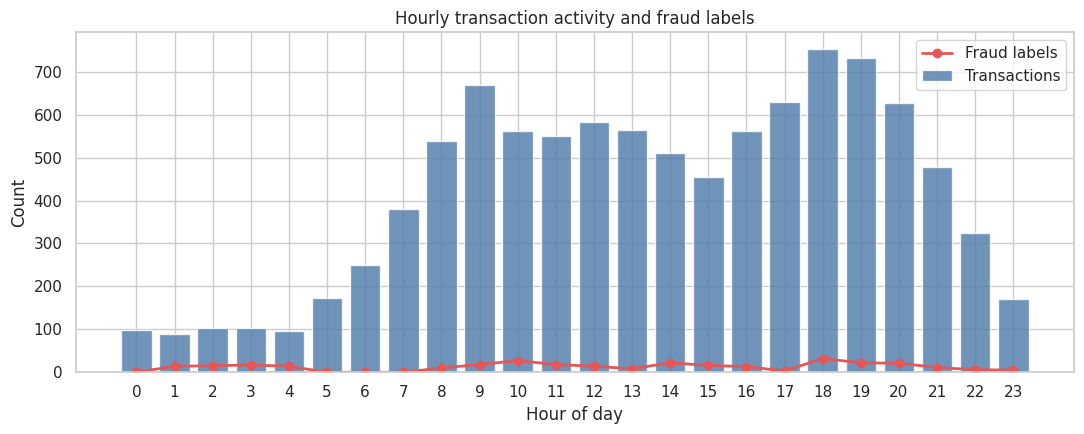

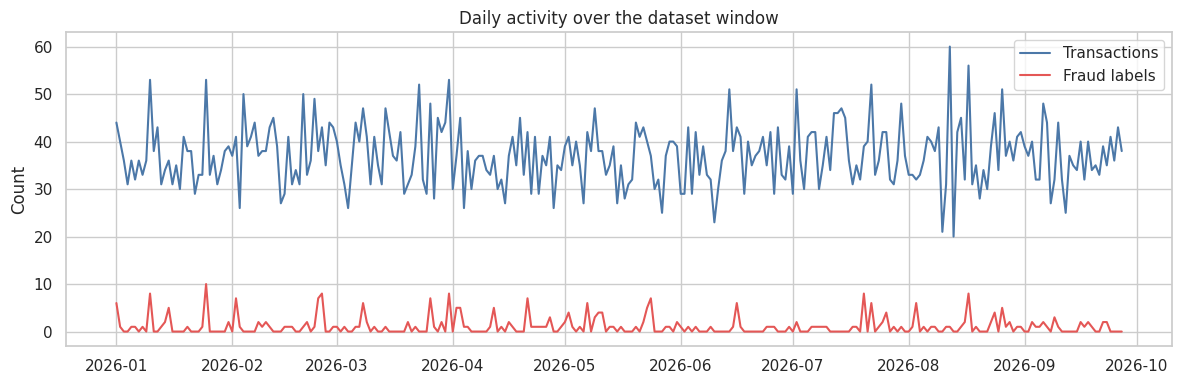

In [6]:
hourly = df.groupby("hour").agg(transactions=("transaction_id", "size"), fraud=("is_fraud", "sum"))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(hourly.index, hourly["transactions"], color="#4c78a8", alpha=.8, label="Transactions")
ax.plot(hourly.index, hourly["fraud"], color="#e45756", marker="o", linewidth=2, label="Fraud labels")
ax.set_xticks(range(24)); ax.set_xlabel("Hour of day"); ax.set_ylabel("Count"); ax.set_title("Hourly transaction activity and fraud labels"); ax.legend()
plt.tight_layout(); plt.savefig(REPORTS / "eda_hourly_patterns.png", dpi=150, bbox_inches="tight"); plt.show()

daily = df.groupby("day").agg(transactions=("transaction_id", "size"), fraud=("is_fraud", "sum"))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily["transactions"], color="#4c78a8", label="Transactions")
ax.plot(daily.index, daily["fraud"], color="#e45756", label="Fraud labels")
ax.set_title("Daily activity over the dataset window"); ax.set_ylabel("Count"); ax.legend()
plt.tight_layout(); plt.savefig(REPORTS / "eda_daily_trend.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Fraud type, category, app and status breakdowns

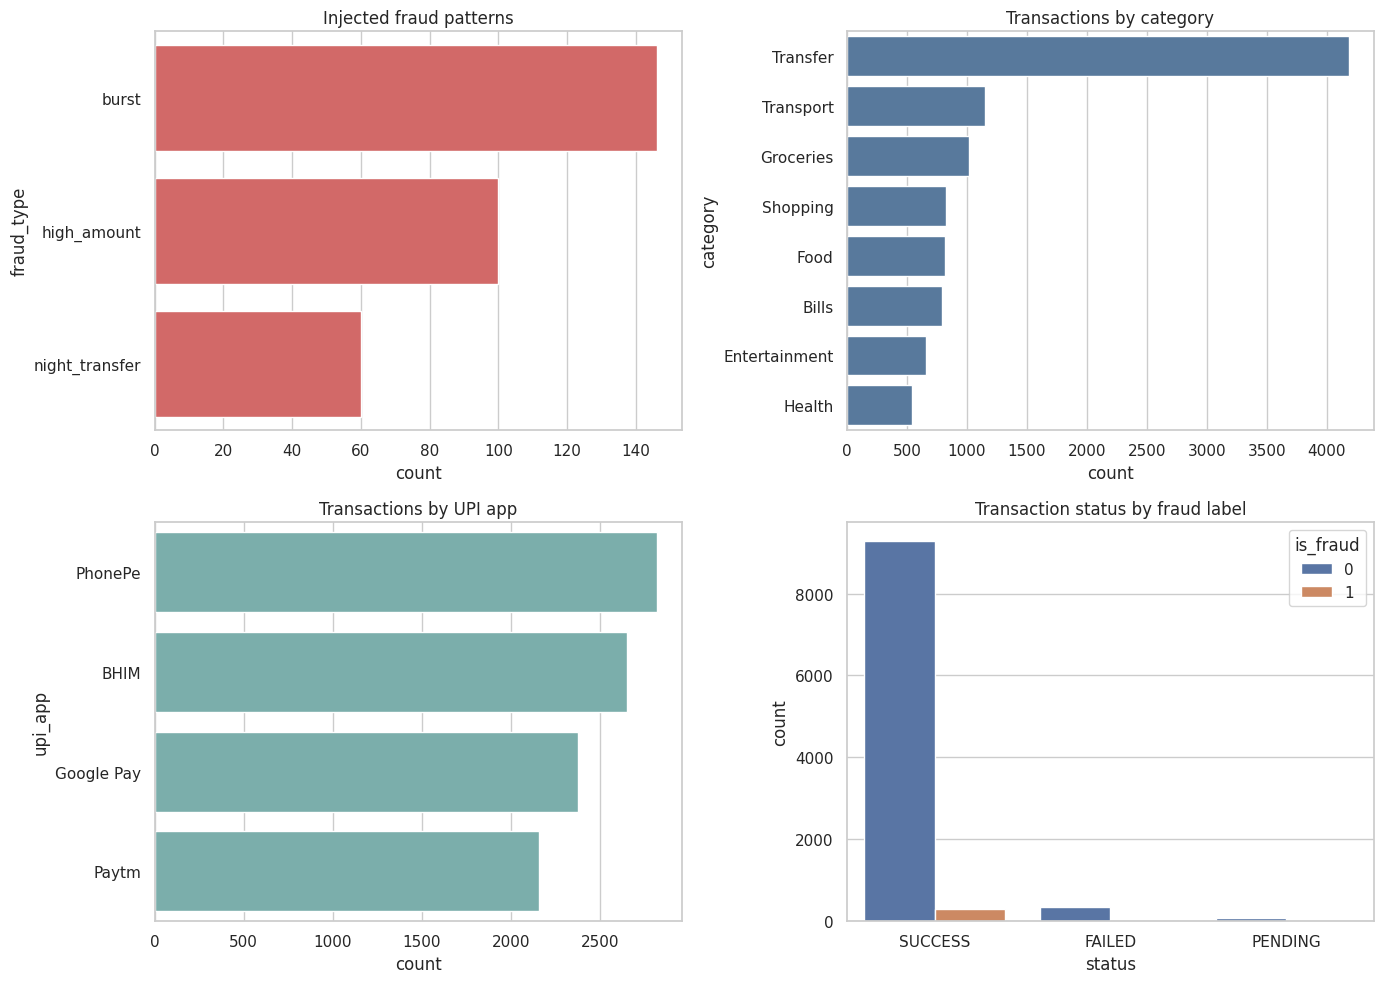

,fraud_transactions
fraud_type,
burst,146
high_amount,100
night_transfer,60


In [7]:
fraud_only = df[df["is_fraud"] == 1]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=fraud_only, y="fraud_type", order=fraud_only["fraud_type"].value_counts().index, ax=axes[0,0], color="#e45756")
axes[0,0].set_title("Injected fraud patterns")
sns.countplot(data=df, y="category", order=df["category"].value_counts().index, ax=axes[0,1], color="#4c78a8")
axes[0,1].set_title("Transactions by category")
sns.countplot(data=df, y="upi_app", order=df["upi_app"].value_counts().index, ax=axes[1,0], color="#72b7b2")
axes[1,0].set_title("Transactions by UPI app")
sns.countplot(data=df, x="status", hue="is_fraud", ax=axes[1,1])
axes[1,1].set_title("Transaction status by fraud label")
plt.tight_layout(); plt.savefig(REPORTS / "eda_segments.png", dpi=150, bbox_inches="tight"); plt.show()

display(fraud_only["fraud_type"].value_counts().to_frame("fraud_transactions"))

## 8. Amount and fraud rate by segment

,transactions,fraud_count,mean_amount,total_value,fraud_rate_pct
category,,,,,
Transfer,4184,306,483.10,2021286.01,7.31
Transport,1153,0,362.57,418040.89,0.00
Groceries,1018,0,355.36,361755.44,0.00
Shopping,823,0,323.42,266174.99,0.00
Food,822,0,344.10,282851.43,0.00
Bills,797,0,317.96,253416.03,0.00
Entertainment,656,0,363.38,238376.98,0.00
Health,547,0,309.04,169046.12,0.00


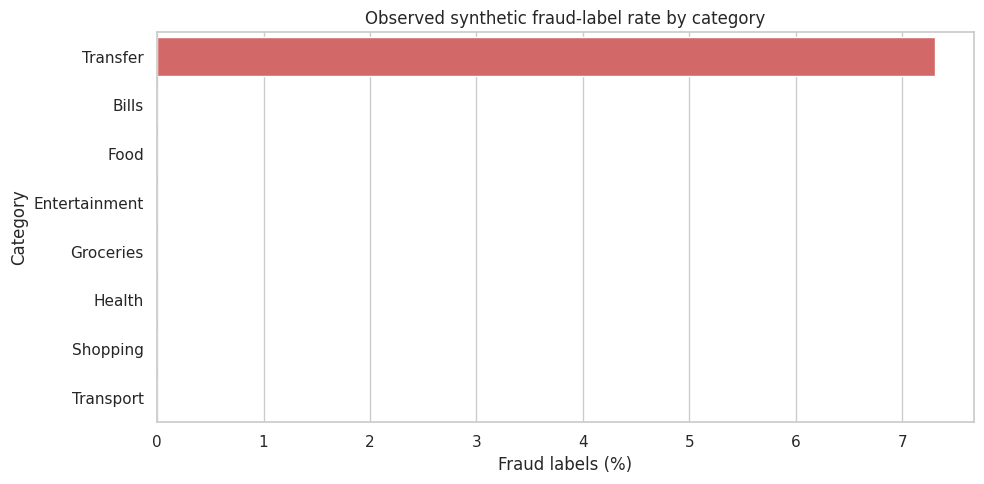

In [8]:
category_summary = df.groupby("category").agg(transactions=("transaction_id", "size"), fraud_count=("is_fraud", "sum"), mean_amount=("amount_inr", "mean"), total_value=("amount_inr", "sum"))
category_summary["fraud_rate_pct"] = (100 * category_summary["fraud_count"] / category_summary["transactions"]).round(2)
display(category_summary.sort_values("transactions", ascending=False).round(2))

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = category_summary.sort_values("fraud_rate_pct", ascending=False)
sns.barplot(x=plot_df["fraud_rate_pct"], y=plot_df.index, ax=ax, color="#e45756")
ax.set_title("Observed synthetic fraud-label rate by category"); ax.set_xlabel("Fraud labels (%)"); ax.set_ylabel("Category")
plt.tight_layout(); plt.savefig(REPORTS / "eda_category_fraud_rate.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Numeric relationships

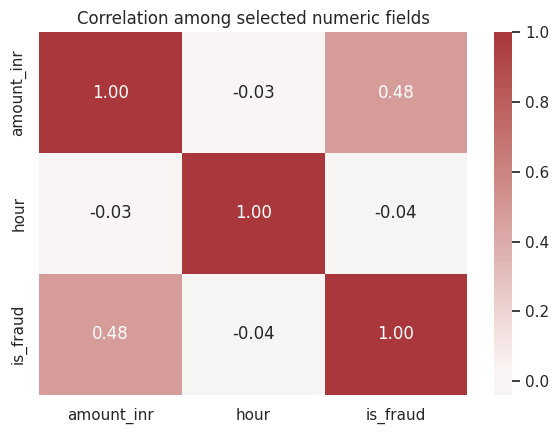

In [9]:
numeric_cols = ["amount_inr", "hour", "is_fraud"]
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(df[numeric_cols].corr(numeric_only=True), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation among selected numeric fields")
plt.tight_layout(); plt.savefig(REPORTS / "eda_correlation.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Findings and interpretation prompts

Use the outputs above to write observations rather than assuming the expected result. In particular:

- Quantify the class imbalance before selecting evaluation metrics.
- Compare fraud and legitimate transaction amounts using both raw and log scales.
- Examine hour-of-day patterns, but remember that some fraud labels were deliberately injected at unusual times.
- Compare the number of labels and the label rate by fraud type and category.
- Avoid interpreting correlations as causal relationships.
- The synthetic generation rules influence these patterns; real payment data could behave very differently.

## 11. Model evaluation report

The training pipeline writes holdout metrics to `reports/metrics.json`. This is a separate time-based holdout evaluation; do not use the holdout labels to tune thresholds.

In [10]:
metrics_path = ROOT / "reports" / "metrics.json"
if metrics_path.exists():
    import json
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    metric_table = pd.DataFrame(metrics.get("holdout", {})).T
    display(metric_table.sort_values("f1", ascending=False))
    print("Threshold selected on training period:", metrics.get("threshold"))
    print("Recall by injected fraud type:", metrics.get("holdout_recall_by_fraud_type", {}))
else:
    print("metrics.json not found. Run python train.py from the project root first.")

,precision,recall,f1,roc_auc
Ensemble,0.904,0.870,0.887,0.984
IQR rule,0.696,0.722,0.709,NaN
Time-series z>3,0.640,0.593,0.615,NaN
Isolation Forest,0.480,0.444,0.462,NaN
Velocity rule,1.000,0.167,0.286,NaN


Threshold selected on training period: 0.42
Recall by injected fraud type: {'burst': 0.6, 'high_amount': 0.966, 'night_transfer': 1.0}


## Conclusion

This EDA describes the supplied synthetic dataset and generates reusable charts in `reports/`. For a portfolio write-up, summarize three to five findings with the exact numbers from your run and explicitly state that the data and fraud labels are synthetic.